# Etapa 2 — Diagnóstico econométrico da série temporal

**Projeto:** canavis — benchmarking regional da cana-de-açúcar na Paraíba
**Usuário final:** Ricardo, gerente agrícola de usina
**Escopo:** explicar o passado. **Sem projeção/forecast** (adiada para a Etapa 3, ADR 0010).

## Hipótese-guia

A série de produtividade (t/ha) da PAM é **curta e limitada**: são **21 pontos anuais**
(2003–2023) por território, sem sazonalidade intra-anual, e com forte supressão abaixo da UF.
Vamos **testar formalmente** se ela sustenta uma afirmação econométrica *confirmatória* de quebra
estrutural, **esperando que o próprio rigor mostre que não** — e isso é um **resultado válido, não
uma falha**. O objetivo é responder ao feedback do professor ("uma mudança visível na série não
basta para afirmar que houve quebra") com evidência, não com um selo.

Este notebook **executa com números reais** os métodos mapeados no ADR 0011. O caso principal é a
**Paraíba** (UF, `uf:25`), série completa de referência, e o **Litoral Norte** (`microrregiao:25020`),
microrregião canavieira usada como série longa sub-UF (ADR 0004/0007). `statsmodels`/`scipy` aparecem
**somente aqui** no notebook; o núcleo do pacote (`src/canavis`) permanece sem essas dependências.


In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# statsmodels/scipy vivem SÓ no notebook (grupo opcional 'notebooks' do pyproject).
from scipy import stats as scipy_stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, zivot_andrews
from statsmodels.tsa.seasonal import STL
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.multitest import multipletests

# Funções PURAS do domínio (sem statsmodels/scipy), reusadas aqui.
from canavis.domain.features import (
    decompor_serie_anual,
    teste_chow,
    varredura_supf,
    fdr_benjamini_hochberg,
)

pd.set_option("display.max_columns", None)
# Ressalvas de poder em n~21 são o próprio achado; não poluímos a saída com avisos repetidos.
warnings.filterwarnings("ignore")

import statsmodels, scipy
print("statsmodels", statsmodels.__version__, "| scipy", scipy.__version__)

statsmodels 0.15.0 | scipy 1.18.1


In [2]:
# Carrega o gold DIRETO do parquet (não reconstrói o pipeline).
fato = pd.read_parquet("../data/processed/fato_producao.parquet")
dim = pd.read_parquet("../data/processed/dim_territorio.parquet")

PB = "uf:25"                 # Paraíba (UF) — série completa de referência
LITORAL_NORTE = "microrregiao:25020"  # microrregião canavieira (série longa sub-UF)

def serie_territorio(territorio_id):
    s = fato[fato["territorio_id"] == territorio_id].sort_values("ano_referencia")
    anos = s["ano_referencia"].reset_index(drop=True)
    y = s["produtividade_t_ha"].astype("float64").reset_index(drop=True)
    return anos, y

anos_pb, y_pb = serie_territorio(PB)
anos_ln, y_ln = serie_territorio(LITORAL_NORTE)

print(f"Fato: {fato.shape}  |  PB: {len(y_pb)} anos  |  Litoral Norte: {len(y_ln)} anos")
print(f"Janela: {int(anos_pb.min())}–{int(anos_pb.max())}")

Fato: (5733, 17)  |  PB: 21 anos  |  Litoral Norte: 21 anos
Janela: 2003–2023


## Passo 1 — Análise descritiva da disposição da série

Antes de qualquer teste, caracterizamos o que temos: **n efetivo**, cobertura/ausências,
supressão por nível, momentos (média, desvio-padrão, coeficiente de variação, assimetria),
extremos e gaps. Cada bloco traz **DECISÃO** e **RESSALVA DE PODER** para n=21.

In [3]:
# Supressão de produtividade por nível (calculada no próprio dado).
supressao = (
    fato.groupby("nivel_territorial")["produtividade_t_ha"]
    .apply(lambda c: 100 * c.isna().mean())
    .round(2)
)
print("Supressão de produtividade por nível (% de ausentes):")
print(supressao.to_string())
print()
print("DECISÃO: série longa só em UF (0% ausente) e microrregião; município tem 61,6% de")
print("supressão -> indefensável para série temporal (ADR 0004).")
print("RESSALVA DE PODER: mesmo em UF/micro, são 21 pontos anuais; tudo a seguir é de baixo poder.")

Supressão de produtividade por nível (% de ausentes):
nivel_territorial
microrregiao    36.44
municipio       61.63
uf               0.00

DECISÃO: série longa só em UF (0% ausente) e microrregião; município tem 61,6% de
supressão -> indefensável para série temporal (ADR 0004).
RESSALVA DE PODER: mesmo em UF/micro, são 21 pontos anuais; tudo a seguir é de baixo poder.


In [4]:
def descritiva(nome, anos, y):
    n = int(y.notna().sum())
    gaps = int(y.isna().sum())
    media = float(y.mean())
    dp = float(y.std(ddof=1))
    cv = 100 * dp / media
    assimetria = float(scipy_stats.skew(y.dropna()))
    return {
        "serie": nome,
        "n_efetivo": n,
        "gaps": gaps,
        "media_t_ha": round(media, 3),
        "dp_t_ha": round(dp, 3),
        "cv_%": round(cv, 2),
        "assimetria": round(assimetria, 3),
        "min_t_ha": round(float(y.min()), 3),
        "max_t_ha": round(float(y.max()), 3),
    }

desc = pd.DataFrame([
    descritiva("Paraíba (UF)", anos_pb, y_pb),
    descritiva("Litoral Norte (micro)", anos_ln, y_ln),
])
desc

,serie,n_efetivo,gaps,media_t_ha,dp_t_ha,cv_%,assimetria,min_t_ha,max_t_ha
0,Paraíba (UF),21,0,53.536,4.209,7.86,0.25,45.647,64.692
1,Litoral Norte (micro),21,0,50.668,5.383,10.62,0.55,41.546,64.825


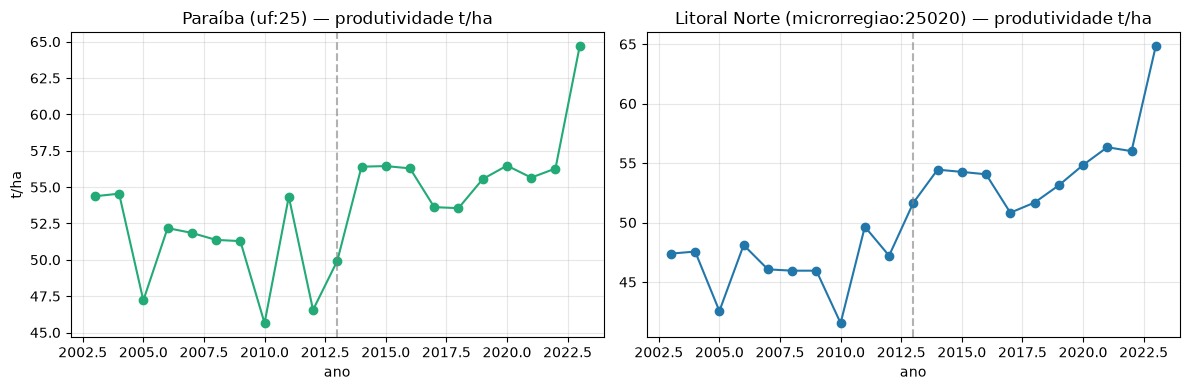

A linha tracejada em 2013 é o ponto de inversão CONHECIDO (ADR 0004): queda até ~2012,
recuperação depois. É candidato exploratório, NÃO quebra confirmada.


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
ax[0].plot(anos_pb, y_pb, marker="o", color="#2a7")
ax[0].set_title("Paraíba (uf:25) — produtividade t/ha")
ax[0].set_xlabel("ano"); ax[0].set_ylabel("t/ha"); ax[0].grid(alpha=0.3)
ax[1].plot(anos_ln, y_ln, marker="o", color="#27a")
ax[1].set_title("Litoral Norte (microrregiao:25020) — produtividade t/ha")
ax[1].set_xlabel("ano"); ax[1].grid(alpha=0.3)
for a in ax:
    a.axvline(2013, color="gray", ls="--", alpha=0.6)  # ponto candidato (ADR 0004)
plt.tight_layout(); plt.show()
print("A linha tracejada em 2013 é o ponto de inversão CONHECIDO (ADR 0004): queda até ~2012,")
print("recuperação depois. É candidato exploratório, NÃO quebra confirmada.")

## Passo 2 — Estacionariedade: ADF e KPSS juntos

ADF e KPSS têm hipóteses nulas **opostas** (ADF H0: raiz unitária; KPSS H0: estacionariedade).
Rodamos os dois em nível, log e 1ª diferença da PB e montamos o **quadrante ADF × KPSS**. Em n~21
o poder é baixíssimo e a distorção de tamanho do KPSS é grande — a leitura é indicativa.

In [6]:
niv = y_pb.to_numpy()
logn = np.log(niv)
dif1 = np.diff(niv)

def adf_p(x):
    r = adfuller(x, autolag="AIC")
    return round(float(r[0]), 4), round(float(r[1]), 4)

def kpss_p(x):
    r = kpss(x, regression="c", nlags="auto")
    return round(float(r[0]), 4), round(float(r[1]), 4)

linhas = []
for nome, x in [("nível", niv), ("log", logn), ("1ª diferença", dif1)]:
    a_stat, a_p = adf_p(x)
    k_stat, k_p = kpss_p(x)
    linhas.append({
        "transformação": nome,
        "ADF_stat": a_stat, "ADF_p": a_p, "ADF_rejeita_raiz(p<0.05)": a_p < 0.05,
        "KPSS_stat": k_stat, "KPSS_p": k_p, "KPSS_rejeita_estac(p<0.05)": k_p < 0.05,
    })
estac = pd.DataFrame(linhas)
estac

,transformação,ADF_stat,ADF_p,ADF_rejeita_raiz(p<0.05),KPSS_stat,KPSS_p,KPSS_rejeita_estac(p<0.05)
0,nível,-2.0068,0.2836,False,0.6504,0.0181,True
1,log,-2.2517,0.1880,False,0.6396,0.0190,True
2,1ª diferença,-1.0597,0.7309,False,0.4156,0.0704,False


In [7]:
print("QUADRANTE ADF × KPSS (nível, PB):")
print(" - ADF não rejeita raiz unitária (p>0,05) e KPSS rejeita estacionariedade (p<0,05):")
print("   quadrante compatível com NÃO-estacionariedade/tendência. Mas é o cenário de menor poder.")
print()
print("DECISÃO: a série em nível não se mostra estacionária; a 1ª diferença também não entrega")
print("estacionariedade limpa (ADF ainda não rejeita) — típico de amostra curtíssima.")
print("RESSALVA DE PODER: com n~21, 'não rejeitar' NÃO prova raiz unitária; é falta de poder.")

QUADRANTE ADF × KPSS (nível, PB):
 - ADF não rejeita raiz unitária (p>0,05) e KPSS rejeita estacionariedade (p<0,05):
   quadrante compatível com NÃO-estacionariedade/tendência. Mas é o cenário de menor poder.

DECISÃO: a série em nível não se mostra estacionária; a 1ª diferença também não entrega
estacionariedade limpa (ADF ainda não rejeita) — típico de amostra curtíssima.
RESSALVA DE PODER: com n~21, 'não rejeitar' NÃO prova raiz unitária; é falta de poder.


## Passo 3 — Raiz unitária com quebra: Zivot-Andrews

O Zivot-Andrews testa raiz unitária **permitindo uma quebra endógena** (data desconhecida) na
constante. É o teste que distingue "quebra determinística" de "random walk". Com 21 pontos há
**distorção de tamanho e poder baixo**; se houver instabilidade numérica, documentamos a ressalva
em vez de mascarar — a limitação é parte do achado.

In [8]:
def za_resultado(nome, x):
    try:
        stat, pval, crit, _, baseidx = zivot_andrews(x, trim=0.15, regression="c")
        ano_quebra = int(anos_pb.min()) + int(baseidx)
        return {"serie": nome, "ZA_stat": round(float(stat), 4), "ZA_p": round(float(pval), 4),
                "crit_5%": round(float(crit["5%"]), 4), "ano_quebra_estimado": ano_quebra,
                "rejeita_raiz(5%)": float(stat) < float(crit["5%"]), "status": "ok"}
    except Exception as e:  # instabilidade em n pequeno: registrar, não esconder
        return {"serie": nome, "ZA_stat": np.nan, "ZA_p": np.nan, "crit_5%": np.nan,
                "ano_quebra_estimado": np.nan, "rejeita_raiz(5%)": np.nan,
                "status": f"{type(e).__name__}: {e}"}

za = pd.DataFrame([za_resultado("PB nível", niv), za_resultado("PB log", logn)])
za

,serie,ZA_stat,ZA_p,crit_5%,ano_quebra_estimado,rejeita_raiz(5%),status
0,PB nível,-4.2056,0.2360,-4.8107,2013,False,ok
1,PB log,-4.6075,0.0906,-4.8107,2013,False,ok


In [9]:
print("DECISÃO: o Zivot-Andrews NÃO rejeita a raiz unitária ao nível de 5% (estatística acima do")
print("crítico), nem em nível nem em log. Ou seja: permitindo uma quebra endógena, o teste ainda")
print("não consegue separar 'quebra determinística' de 'passeio aleatório' nesta série.")
print("RESSALVA DE PODER: Nelson/Piger/Zivot mostram poder baixíssimo desses testes contra")
print("tendência com mudança de regime; com 21 pontos é impraticável cravar — não rejeitar não prova.")

DECISÃO: o Zivot-Andrews NÃO rejeita a raiz unitária ao nível de 5% (estatística acima do
crítico), nem em nível nem em log. Ou seja: permitindo uma quebra endógena, o teste ainda
não consegue separar 'quebra determinística' de 'passeio aleatório' nesta série.
RESSALVA DE PODER: Nelson/Piger/Zivot mostram poder baixíssimo desses testes contra
tendência com mudança de regime; com 21 pontos é impraticável cravar — não rejeitar não prova.


## Passo 4 — Transformações (log, 1ª diferença) e normalidade dos resíduos

Ajustamos uma tendência linear à PB (em nível e em log) e testamos a **normalidade dos resíduos**
por Jarque-Bera (statsmodels) e Shapiro-Wilk (scipy). Normalidade dos resíduos é pré-condição para
a inferência F do Chow.

In [10]:
X = sm.add_constant(anos_pb.to_numpy(dtype=float) - anos_pb.mean())
res_niv = sm.OLS(niv, X).fit().resid
res_log = sm.OLS(logn, X).fit().resid

def normalidade(nome, res):
    jb_stat, jb_p = jarque_bera(res)[:2]
    sh_stat, sh_p = scipy_stats.shapiro(res)
    return {"residuos": nome,
            "JarqueBera_stat": round(float(jb_stat), 4), "JB_p": round(float(jb_p), 4),
            "Shapiro_stat": round(float(sh_stat), 4), "Shapiro_p": round(float(sh_p), 4),
            "normal(p>0.05)": (jb_p > 0.05) and (sh_p > 0.05)}

norm = pd.DataFrame([normalidade("tendência nível (PB)", res_niv),
                     normalidade("tendência log (PB)", res_log)])
norm

,residuos,JarqueBera_stat,JB_p,Shapiro_stat,Shapiro_p,normal(p>0.05)
0,tendência nível (PB),0.0248,0.9877,0.9734,0.8061,True
1,tendência log (PB),0.4392,0.8028,0.9634,0.5860,True


In [11]:
print("DECISÃO: os resíduos da tendência linear NÃO rejeitam normalidade (JB e Shapiro p>0,05),")
print("tanto em nível quanto em log. A condição de normalidade é compatível; o log não é necessário")
print("para normalizar — mantemos o nível como leitura principal e o log como checagem.")
print("RESSALVA DE PODER: testes de normalidade com n~21 têm pouco poder para detectar desvios.")

DECISÃO: os resíduos da tendência linear NÃO rejeitam normalidade (JB e Shapiro p>0,05),
tanto em nível quanto em log. A condição de normalidade é compatível; o log não é necessário
para normalizar — mantemos o nível como leitura principal e o log como checagem.
RESSALVA DE PODER: testes de normalidade com n~21 têm pouco poder para detectar desvios.


## Passo 5 — Decomposição tendência/oscilação: MM-3 × LOESS × STL

Comparamos a **média móvel centrada de 3 anos** (`decompor_serie_anual`, já no pacote) com **LOESS**
e **STL** (statsmodels). A série é **anual, sem sazonalidade intra-anual**: o STL só roda com um
período mínimo forçado (`period=2`), de forma **ilustrativa** — documentar que a série **não comporta
STL sazonal** é resultado, não falha. O **filtro HP** é citado com ressalva de ciclo espúrio e
instabilidade nas pontas (2023). A leitura honesta usa MM-3/LOESS.

MM-3: 19 pontos de tendência (bordas nulas).
STL (period=2, ILUSTRATIVO): sazonal |máx| = 2.010 t/ha
  -> a 'sazonalidade' é artefato do período forçado; a série ANUAL não comporta STL sazonal.


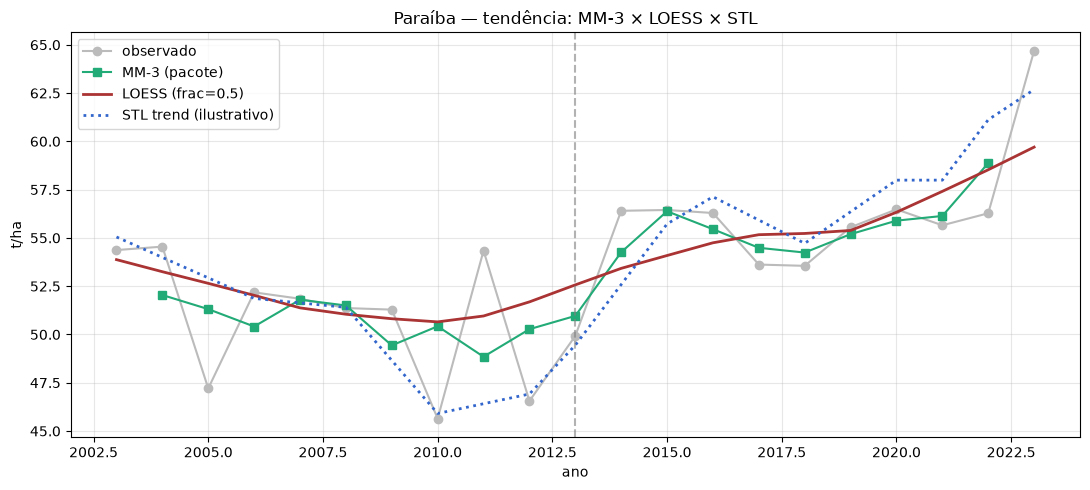

In [12]:
comp = decompor_serie_anual(anos_pb, y_pb)
loess_pb = lowess(niv, anos_pb.to_numpy(dtype=float), frac=0.5, return_sorted=False)

idx = pd.period_range(str(int(anos_pb.min())), periods=len(niv), freq="Y").to_timestamp()
stl_fit = STL(pd.Series(niv, index=idx), period=2, robust=True).fit()

print(f"MM-3: {int(comp['tendencia_t_ha'].notna().sum())} pontos de tendência (bordas nulas).")
print(f"STL (period=2, ILUSTRATIVO): sazonal |máx| = {float(np.abs(stl_fit.seasonal).max()):.3f} t/ha")
print("  -> a 'sazonalidade' é artefato do período forçado; a série ANUAL não comporta STL sazonal.")

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(anos_pb, y_pb, marker="o", color="#bbb", label="observado")
ax.plot(anos_pb, comp["tendencia_t_ha"], marker="s", color="#2a7", label="MM-3 (pacote)")
ax.plot(anos_pb, loess_pb, color="#a33", lw=2, label="LOESS (frac=0.5)")
ax.plot(anos_pb, stl_fit.trend.to_numpy(), color="#36c", ls=":", lw=2, label="STL trend (ilustrativo)")
ax.axvline(2013, color="gray", ls="--", alpha=0.6)
ax.set_title("Paraíba — tendência: MM-3 × LOESS × STL"); ax.set_xlabel("ano"); ax.set_ylabel("t/ha")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [13]:
print("DECISÃO: MM-3 e LOESS concordam no desenho 'queda até ~2012, recuperação até 2023' e são a")
print("leitura honesta. STL é mantido apenas como ilustração de que a série não sustenta componente")
print("sazonal. Filtro HP NÃO é usado: geraria ciclo espúrio e é instável nas pontas (pico de 2023).")
print("RESSALVA DE PODER: com 21 pontos, qualquer suavização nas bordas (2003, 2023) é frágil.")

DECISÃO: MM-3 e LOESS concordam no desenho 'queda até ~2012, recuperação até 2023' e são a
leitura honesta. STL é mantido apenas como ilustração de que a série não sustenta componente
sazonal. Filtro HP NÃO é usado: geraria ciclo espúrio e é instável nas pontas (pico de 2023).
RESSALVA DE PODER: com 21 pontos, qualquer suavização nas bordas (2003, 2023) é frágil.


## Passo 6 — Quebra com ponto ENDÓGENO: supF / Quandt-Andrews × Chow fixo

O Chow de ponto fixo (2013) sofre o viés de ter escolhido a data **olhando os dados** (ADR 0009).
O supF (Quandt-Andrews) **varre** todos os cortes internos de uma janela aparada (~15%) e toma o F
máximo — corrige o viés do ponto garimpado. Usamos a função pura `varredura_supf` e comparamos com
`teste_chow` fixo em 2013. Mostramos que, **sem fixar o ponto a olho**, a evidência permanece
exploratória.

In [14]:
def comparar(nome, anos, y):
    chow = teste_chow(anos, y)                 # ponto fixo 2013
    supf = varredura_supf(anos, y, aparagem=0.15)  # ponto endógeno
    return {
        "serie": nome,
        "Chow_F(2013 fixo)": round(chow["f_chow"], 4), "Chow_p": round(chow["p_chow"], 4),
        "supF(endógeno)": round(supf["sup_f"], 4), "ano_supF": int(supf["ano_sup"]),
        "n_cortes": supf["n_cortes"], "status_supF": supf["status"],
    }

quebra = pd.DataFrame([comparar("Paraíba (UF)", anos_pb, y_pb),
                       comparar("Litoral Norte", anos_ln, y_ln)])
quebra

,serie,Chow_F(2013 fixo),Chow_p,supF(endógeno),ano_supF,n_cortes,status_supF
0,Paraíba (UF),4.2513,0.0318,4.9564,2013,12,endogeno
1,Litoral Norte,2.9039,0.0822,4.6089,2010,12,endogeno


In [15]:
print("LEITURA (atenção ao valor crítico):")
print(" - O p do Chow fixo usa F(2, n-4); o supF NÃO pode ser lido nessa mesma tabela F, porque")
print("   maximizar sobre ~12 cortes infla a estatística. Os críticos de Quandt-Andrews a 5% para")
print("   2 parâmetros e aparagem 15% ficam na faixa de ~11-12 (Stock & Watson) — bem acima dos")
print("   supF observados (PB 4,96; Litoral Norte 4,61).")
print(" - PB: o supF endógeno maximiza EXATAMENTE em 2013 (o mesmo ponto do ADR 0004), com sup_f")
print("   4,96, mas longe do crítico de Andrews: a busca endógena NÃO eleva a evidência.")
print(" - Litoral Norte: o supF maximiza em 2010, nem no ponto 'conhecido' — reforça que o corte a")
print("   olho é frágil fora da UF.")
print("DECISÃO: sem fixar o ponto a olho, a evidência de quebra continua EXPLORATÓRIA.")
print("RESSALVA DE PODER: a aparagem de 15% corta ainda mais os já escassos 21 pontos.")

LEITURA (atenção ao valor crítico):
 - O p do Chow fixo usa F(2, n-4); o supF NÃO pode ser lido nessa mesma tabela F, porque
   maximizar sobre ~12 cortes infla a estatística. Os críticos de Quandt-Andrews a 5% para
   2 parâmetros e aparagem 15% ficam na faixa de ~11-12 (Stock & Watson) — bem acima dos
   supF observados (PB 4,96; Litoral Norte 4,61).
 - PB: o supF endógeno maximiza EXATAMENTE em 2013 (o mesmo ponto do ADR 0004), com sup_f
   4,96, mas longe do crítico de Andrews: a busca endógena NÃO eleva a evidência.
 - Litoral Norte: o supF maximiza em 2010, nem no ponto 'conhecido' — reforça que o corte a
   olho é frágil fora da UF.
DECISÃO: sem fixar o ponto a olho, a evidência de quebra continua EXPLORATÓRIA.
RESSALVA DE PODER: a aparagem de 15% corta ainda mais os já escassos 21 pontos.


## Passo 7 — Diagnóstico dos resíduos: Ljung-Box e Breusch-Pagan

O Chow supõe erros **independentes e homocedásticos**. Testamos autocorrelação residual
(Ljung-Box) e heterocedasticidade (Breusch-Pagan) sobre a regressão de tendência da PB.

In [16]:
lb = acorr_ljungbox(res_niv, lags=[1, 2], return_df=True).round(4)
bp_lm, bp_lm_p, bp_f, bp_f_p = het_breuschpagan(res_niv, X)
print("Ljung-Box (autocorrelação dos resíduos, PB nível):")
print(lb.to_string())
print()
print(f"Breusch-Pagan (heterocedasticidade): LM = {bp_lm:.4f} (p = {bp_lm_p:.4f}) | "
      f"F = {bp_f:.4f} (p = {bp_f_p:.4f})")
print()
print("DECISÃO: Ljung-Box NÃO acusa autocorrelação (p>0,05 em lag 1 e 2) e Breusch-Pagan NÃO acusa")
print("heterocedasticidade (p>0,05). As suposições do Chow não são violadas de forma detectável —")
print("mas isso NÃO valida inferência confirmatória, porque o problema do ponto garimpado e da")
print("multiplicidade permanece (Passos 6 e 8).")
print("RESSALVA DE PODER: com n~21, esses diagnósticos quase não têm poder para flagrar violações.")

Ljung-Box (autocorrelação dos resíduos, PB nível):
   lb_stat  lb_pvalue
1   0.0194     0.8893
2   0.0387     0.9808

Breusch-Pagan (heterocedasticidade): LM = 0.0688 (p = 0.7931) | F = 0.0624 (p = 0.8054)

DECISÃO: Ljung-Box NÃO acusa autocorrelação (p>0,05 em lag 1 e 2) e Breusch-Pagan NÃO acusa
heterocedasticidade (p>0,05). As suposições do Chow não são violadas de forma detectável —
mas isso NÃO valida inferência confirmatória, porque o problema do ponto garimpado e da
multiplicidade permanece (Passos 6 e 8).
RESSALVA DE PODER: com n~21, esses diagnósticos quase não têm poder para flagrar violações.


## Passo 8 — Múltiplas comparações: FDR de Benjamini-Hochberg

Testar ~40 territórios a α=0,05 produz ~2 falsos positivos só por acaso. A contagem exploratória do
ADR 0009 ("p<0,05 em 15 UFs e 8 microrregiões") **precisa de correção**. Recalculamos o Chow por
território elegível e aplicamos o **FDR de Benjamini-Hochberg**, pela função pura
`fdr_benjamini_hochberg` e por `statsmodels.stats.multitest.multipletests` (conferência cruzada).

In [17]:
elegivel = fato[fato["nivel_territorial"].isin(["uf", "microrregiao"])]
regs = []
for tid, g in elegivel.groupby("territorio_id"):
    gg = g.sort_values("ano_referencia")
    t = teste_chow(gg["ano_referencia"], gg["produtividade_t_ha"].astype("float64"))
    regs.append({"territorio_id": tid, "nivel": gg["nivel_territorial"].iloc[0],
                 "p_chow": t["p_chow"], "status": t["status_chow"]})
tabela = pd.DataFrame(regs)
calc = tabela[tabela["status"] == "exploratorio"].reset_index(drop=True)

n_uf = int((calc["nivel"] == "uf").sum())
n_micro = int((calc["nivel"] == "microrregiao").sum())
nominal = calc[calc["p_chow"] < 0.05]
print(f"Chow calculável em {len(calc)} territórios ({n_uf} UF + {n_micro} micro).")
print(f"p NOMINAL < 0,05 em {len(nominal)} "
      f"({int((nominal.nivel=='uf').sum())} UF + {int((nominal.nivel=='microrregiao').sum())} micro) "
      f"-> contagem EXPLORATÓRIA do ADR 0009.")

Chow calculável em 40 territórios (27 UF + 13 micro).
p NOMINAL < 0,05 em 23 (15 UF + 8 micro) -> contagem EXPLORATÓRIA do ADR 0009.


In [18]:
pvs = pd.Series(calc["p_chow"].to_numpy())
bh = fdr_benjamini_hochberg(pvs, alfa=0.05)
sm_rej, sm_padj, _, _ = multipletests(calc["p_chow"].to_numpy(), alpha=0.05, method="fdr_bh")

calc = calc.assign(p_ajustado_bh=np.round(bh["p_ajustado"], 4), sobrevive_fdr=bh["rejeitado"])
sobrev = calc[calc["sobrevive_fdr"]]
s_uf = int((sobrev["nivel"] == "uf").sum())
s_micro = int((sobrev["nivel"] == "microrregiao").sum())

print(f"FDR Benjamini-Hochberg (α=0,05): {bh['n_rejeitado']} de {bh['n_total']} territórios SOBREVIVEM")
print(f"  -> {s_uf} UF + {s_micro} micro  (conferência statsmodels: {int(sm_rej.sum())} rejeitados).")
print()
print("REESCRITA DA CONTAGEM DO ADR 0009:")
print(f"  antes (nominal): p<0,05 em 15 UFs e 8 microrregiões (= 23).")
print(f"  depois (FDR):   {s_uf} UFs e {s_micro} microrregiões (= {bh['n_rejeitado']}) sobrevivem ao controle.")
print()
pb_adj = float(calc.loc[calc.territorio_id == 'uf:25', 'p_ajustado_bh'].iloc[0])
pb_sobrev = bool(calc.loc[calc.territorio_id == 'uf:25', 'sobrevive_fdr'].iloc[0])
print(f"CASO PRINCIPAL — Paraíba: p nominal 0,0318 -> p ajustado BH {pb_adj:.4f}; "
      f"sobrevive ao FDR? {pb_sobrev}.")
print("  A PB é o PRIMEIRO território que NÃO sobrevive ao controle: o caso-vitrine cai justamente")
print("  quando se corrige a multiplicidade. É o resultado mais eloquente contra afirmar quebra.")

FDR Benjamini-Hochberg (α=0,05): 20 de 40 territórios SOBREVIVEM
  -> 13 UF + 7 micro  (conferência statsmodels: 20 rejeitados).

REESCRITA DA CONTAGEM DO ADR 0009:
  antes (nominal): p<0,05 em 15 UFs e 8 microrregiões (= 23).
  depois (FDR):   13 UFs e 7 microrregiões (= 20) sobrevivem ao controle.

CASO PRINCIPAL — Paraíba: p nominal 0,0318 -> p ajustado BH 0.0606; sobrevive ao FDR? False.
  A PB é o PRIMEIRO território que NÃO sobrevive ao controle: o caso-vitrine cai justamente
  quando se corrige a multiplicidade. É o resultado mais eloquente contra afirmar quebra.


In [19]:
calc.sort_values("p_chow").reset_index(drop=True)

,territorio_id,nivel,p_chow,status,p_ajustado_bh,sobrevive_fdr
0,uf:12,uf,0.000001,exploratorio,0.0001,True
1,microrregiao:25021,microrregiao,0.000012,exploratorio,0.0002,True
2,uf:31,uf,0.000014,exploratorio,0.0002,True
3,uf:29,uf,0.000080,exploratorio,0.0008,True
4,uf:23,uf,0.000184,exploratorio,0.0015,True
5,microrregiao:25003,microrregiao,0.000316,exploratorio,0.0021,True
6,uf:14,uf,0.000376,exploratorio,0.0021,True
7,uf:11,uf,0.000531,exploratorio,0.0024,True
8,uf:32,uf,0.000542,exploratorio,0.0024,True
9,uf:53,uf,0.001380,exploratorio,0.0055,True


## Passo 9 — Síntese e gate

Consolidamos teste / resultado / ressalva e confirmamos o **gate do ADR 0009**: a série **não
sustenta** afirmação confirmatória de quebra. A leitura defensável é **descritiva**.

In [20]:
sintese = pd.DataFrame([
    ["Descritiva (Passo 1)", "n=21; CV 7,9%; assimetria 0,25; 61,6% supressão município",
     "amostra curtíssima; só UF/micro sustentam série longa"],
    ["ADF × KPSS (Passo 2)", "nível: ADF não rejeita raiz (p=0,28) / KPSS rejeita estac. (p=0,02)",
     "poder baixíssimo e distorção de tamanho do KPSS em n~21"],
    ["Zivot-Andrews (Passo 3)", "nível ZA=-4,21 (p=0,24); não rejeita raiz a 5%",
     "não separa quebra de random walk; poder baixo"],
    ["Normalidade (Passo 4)", "JB p=0,99; Shapiro p=0,81; resíduos normais",
     "pouco poder para detectar não-normalidade"],
    ["Decomposição (Passo 5)", "MM-3 e LOESS: queda até ~2012, recuperação até 2023",
     "STL sazonal não cabe; HP geraria ciclo espúrio"],
    ["supF endógeno (Passo 6)", "PB supF=4,96 em 2013; LN supF=4,61 em 2010; << crítico Andrews",
     "sem fixar ponto a olho, segue exploratório"],
    ["Resíduos (Passo 7)", "Ljung-Box p>0,88; Breusch-Pagan p=0,79; sem violação detectável",
     "diagnósticos sem poder em n~21"],
    ["FDR (Passo 8)", "23 nominais -> 20 sobrevivem (13 UF + 7 micro); PB NÃO sobrevive",
     "multiplicidade derruba a contagem; derruba o caso-vitrine"],
], columns=["teste", "resultado", "ressalva de poder"])
sintese

,teste,resultado,ressalva de poder
0,Descritiva (Passo 1),"n=21; CV 7,9%; assimetria 0,25; 61,6% supressã...",amostra curtíssima; só UF/micro sustentam séri...
1,ADF × KPSS (Passo 2),"nível: ADF não rejeita raiz (p=0,28) / KPSS re...",poder baixíssimo e distorção de tamanho do KPS...
2,Zivot-Andrews (Passo 3),"nível ZA=-4,21 (p=0,24); não rejeita raiz a 5%",não separa quebra de random walk; poder baixo
3,Normalidade (Passo 4),"JB p=0,99; Shapiro p=0,81; resíduos normais",pouco poder para detectar não-normalidade
4,Decomposição (Passo 5),"MM-3 e LOESS: queda até ~2012, recuperação até...",STL sazonal não cabe; HP geraria ciclo espúrio
5,supF endógeno (Passo 6),"PB supF=4,96 em 2013; LN supF=4,61 em 2010; <<...","sem fixar ponto a olho, segue exploratório"
6,Resíduos (Passo 7),"Ljung-Box p>0,88; Breusch-Pagan p=0,79; sem vi...",diagnósticos sem poder em n~21
7,FDR (Passo 8),23 nominais -> 20 sobrevivem (13 UF + 7 micro)...,multiplicidade derruba a contagem; derruba o c...


In [21]:
print("GATE (confirma o ADR 0009):")
print("A série de produtividade da PAM — 21 pontos anuais, forte supressão sub-UF, sem sazonalidade")
print("— NÃO sustenta afirmação CONFIRMATÓRIA de quebra estrutural. A busca de ponto endógeno (supF)")
print("recai no mesmo 2013 da PB mas fica muito abaixo do crítico de Andrews; o Zivot-Andrews não")
print("separa quebra de random walk; e a correção de multiplicidade (FDR) derruba o próprio caso da")
print("PB. Cada 'não rejeita' é FALTA DE PODER, não prova de ausência de quebra.")
print()
print("LEITURA DEFENSÁVEL (descritiva): 'observa-se queda até ~2012 e recuperação até 2023; a")
print("diferença entre os dois períodos é SUGESTIVA em teste exploratório'. No painel: 'divisão")
print("exploratória' em 2013, nunca 'quebra confirmada'; coluna quebra_confirmada permanece nula.")
print()
print("ENCAMINHAMENTO: a modelagem econométrica de série longa cabe às séries INTERNACIONAIS de")
print("preço/câmbio/balanço por país (ADR 0010), na Etapa 3 — SEM qualquer projeção/forecast aqui.")

GATE (confirma o ADR 0009):
A série de produtividade da PAM — 21 pontos anuais, forte supressão sub-UF, sem sazonalidade
— NÃO sustenta afirmação CONFIRMATÓRIA de quebra estrutural. A busca de ponto endógeno (supF)
recai no mesmo 2013 da PB mas fica muito abaixo do crítico de Andrews; o Zivot-Andrews não
separa quebra de random walk; e a correção de multiplicidade (FDR) derruba o próprio caso da
PB. Cada 'não rejeita' é FALTA DE PODER, não prova de ausência de quebra.

LEITURA DEFENSÁVEL (descritiva): 'observa-se queda até ~2012 e recuperação até 2023; a
diferença entre os dois períodos é SUGESTIVA em teste exploratório'. No painel: 'divisão
exploratória' em 2013, nunca 'quebra confirmada'; coluna quebra_confirmada permanece nula.

ENCAMINHAMENTO: a modelagem econométrica de série longa cabe às séries INTERNACIONAIS de
preço/câmbio/balanço por país (ADR 0010), na Etapa 3 — SEM qualquer projeção/forecast aqui.
